In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/clean/rtt_clean.csv", parse_dates=["month"])

def summarise(data, by):
    out = data.groupby(by)[["waiting_list", "known_start", "within_18wks", "over_52wks"]].sum()
    out["pct_within_18wks"] = (out["within_18wks"] / out["known_start"] * 100).round(1)
    return out

In [2]:
national = summarise(df, "month")
national

,waiting_list,known_start,within_18wks,over_52wks,pct_within_18wks
month,,,,,
2025-04-01,7421453,7421453.0,4430301.0,192560.0,59.7
2026-03-01,7045510,7045510.0,4596622.0,95824.0,65.2


In [3]:
latest = df[df["month"] == df["month"].max()]
spec = summarise(latest, "specialty").sort_values("pct_within_18wks")
spec

,waiting_list,known_start,within_18wks,over_52wks,pct_within_18wks
specialty,,,,,
Oral Surgery Service,320612,320612.0,178101.0,7091.0,55.6
Plastic Surgery Service,101370,101370.0,57379.0,2464.0,56.6
Ear Nose and Throat Service,580054,580054.0,338817.0,12596.0,58.4
Trauma and Orthopaedic Service,826172,826172.0,488079.0,18999.0,59.1
Neurology Service,208673,208673.0,126368.0,2075.0,60.6
Gynaecology Service,555528,555528.0,337944.0,10033.0,60.8
Neurosurgical Service,56423,56423.0,35100.0,776.0,62.2
General Surgery Service,376693,376693.0,237010.0,5927.0,62.9
Dermatology Service,372060,372060.0,241996.0,3653.0,65.0


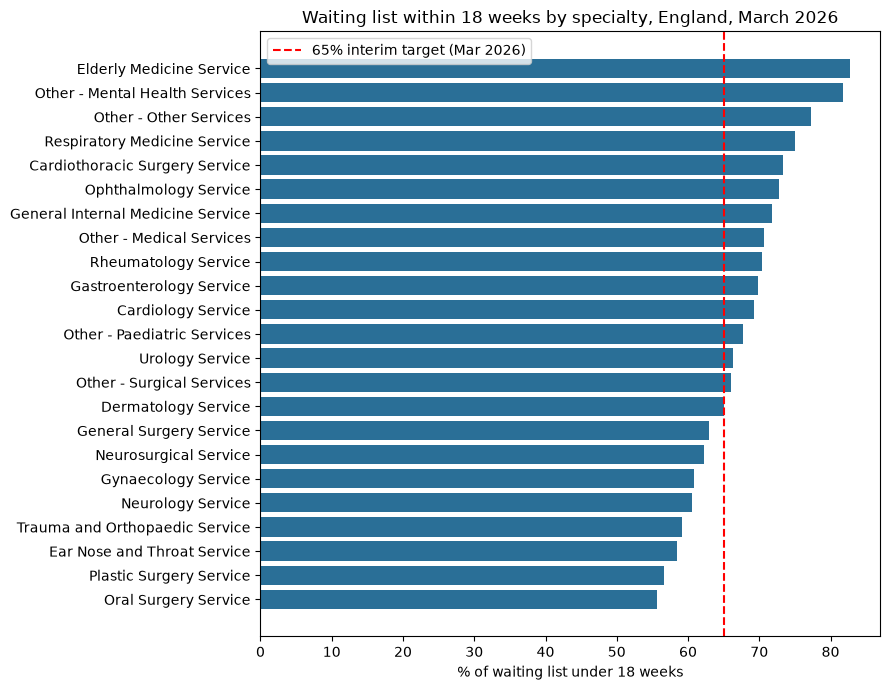

In [4]:
plt.figure(figsize=(9, 7))
plt.barh(spec.index, spec["pct_within_18wks"], color="#2a6f97")
plt.axvline(65, color="red", linestyle="--", label="65% interim target (Mar 2026)")
plt.xlabel("% of waiting list under 18 weeks")
plt.title("Waiting list within 18 weeks by specialty, England, March 2026")
plt.legend()
plt.tight_layout()
plt.savefig("specialty_18wks.png", dpi=150)
plt.show()

In [5]:
print("Largest waiting lists:")
print(spec.sort_values("waiting_list", ascending=False)["waiting_list"].head(5))
print("\nMost 52+ week waits:")
print(spec.sort_values("over_52wks", ascending=False)["over_52wks"].head(5))

Largest waiting lists:
specialty
Trauma and Orthopaedic Service    826172
Other - Medical Services          614175
Ophthalmology Service             603966
Ear Nose and Throat Service       580054
Gynaecology Service               555528
Name: waiting_list, dtype: int64

Most 52+ week waits:
specialty
Trauma and Orthopaedic Service    18999.0
Ear Nose and Throat Service       12596.0
Gynaecology Service               10033.0
Oral Surgery Service               7091.0
General Surgery Service            5927.0
Name: over_52wks, dtype: float64


In [6]:
change = summarise(df, ["specialty", "month"])["pct_within_18wks"].unstack()
change.columns = ["Apr 2025", "Mar 2026"]
change["change_pts"] = (change["Mar 2026"] - change["Apr 2025"]).round(1)
change.sort_values("change_pts")

,Apr 2025,Mar 2026,change_pts
specialty,,,
Elderly Medicine Service,81.7,82.8,1.1
Plastic Surgery Service,53.9,56.6,2.7
Trauma and Orthopaedic Service,56.4,59.1,2.7
Neurosurgical Service,58.8,62.2,3.4
General Surgery Service,59.1,62.9,3.8
General Internal Medicine Service,68.0,71.8,3.8
Ophthalmology Service,68.8,72.8,4.0
Rheumatology Service,66.3,70.4,4.1
Other - Other Services,72.9,77.2,4.3


In [7]:
summarise(latest, "provider_type")

,waiting_list,known_start,within_18wks,over_52wks,pct_within_18wks
provider_type,,,,,
Independent sector,438136,438136.0,324263.0,2338.0,74.0
NHS trust,6607374,6607374.0,4272359.0,93486.0,64.7


In [8]:
trusts = summarise(latest[latest["provider_type"] == "NHS trust"], ["org_code", "trust"])
trusts = trusts[trusts["waiting_list"] >= 10000].sort_values("pct_within_18wks")
print("Trusts compared:", len(trusts))
print("Trusts at or above 65%:", (trusts["pct_within_18wks"] >= 65).sum())
trusts.head(5)

Trusts compared: 128
Trusts at or above 65%: 59


,,waiting_list,known_start,within_18wks,over_52wks,pct_within_18wks
org_code,trust,,,,,
RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,173977,173977.0,88038.0,12150.0,50.6
RL1,THE ROBERT JONES AND AGNES HUNT ORTHOPAEDIC HOSPITAL NHS FOUNDATION TRUST,23933,23933.0,12533.0,2814.0,52.4
RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,112535,112535.0,62009.0,3580.0,55.1
RGP,JAMES PAGET UNIVERSITY HOSPITALS NHS FOUNDATION TRUST,32827,32827.0,18217.0,1305.0,55.5
RDR,SUSSEX COMMUNITY NHS FOUNDATION TRUST,13174,13174.0,7315.0,119.0,55.5


In [9]:
summarise(latest, "icb").sort_values("pct_within_18wks")

,waiting_list,known_start,within_18wks,over_52wks,pct_within_18wks
icb,,,,,
NHS MID AND SOUTH ESSEX INTEGRATED CARE BOARD,183223,183223.0,94892.0,12320.0,51.8
"NHS LEICESTER, LEICESTERSHIRE AND RUTLAND INTEGRATED CARE BOARD",117684,117684.0,70303.0,2337.0,59.7
NHS SUSSEX INTEGRATED CARE BOARD,222854,222854.0,134087.0,4504.0,60.2
NHS HUMBER AND NORTH YORKSHIRE INTEGRATED CARE BOARD,207981,207981.0,125429.0,4616.0,60.3
NHS LINCOLNSHIRE INTEGRATED CARE BOARD,71337,71337.0,43378.0,431.0,60.8
NHS FRIMLEY INTEGRATED CARE BOARD,69137,69137.0,42389.0,622.0,61.3
NHS NORFOLK AND WAVENEY INTEGRATED CARE BOARD,129442,129442.0,79395.0,3363.0,61.3
NHS CAMBRIDGESHIRE AND PETERBOROUGH INTEGRATED CARE BOARD,154080,154080.0,95501.0,1594.0,62.0
NHS SUFFOLK AND NORTH EAST ESSEX INTEGRATED CARE BOARD,121945,121945.0,75732.0,707.0,62.1


## Key findings

1. **England reached the 65% interim target by March 2026.** The share of the waiting list under 18 weeks rose from 59.7% (April 2025) to 65.2% (March 2026), still well below the 92% constitutional standard.
2. **The waiting list fell 5.1%**, from 7,421,453 to 7,045,510 (–375,943).
3. **52-week waits halved**, from 192,560 to 95,824.
4. **All 23 specialties improved, but 8 remain below 65%.** Oral surgery is lowest (55.6%), followed by plastic surgery (56.6%), ENT (58.4%) and trauma & orthopaedics (59.1%). Respiratory medicine improved most (+11.0 points); elderly medicine (+1.1), trauma & orthopaedics (+2.7) and plastic surgery (+2.7) improved least.
5. **Trauma & orthopaedics is the biggest pressure point:** the largest list (826,172) and 19,000 52-week waits, about 20% of England's total.
6. **Long waits are concentrated.** Mid and South Essex NHS FT had the lowest 18-week performance of large trusts (50.6%) and 12,150 52-week waits, about 13% of the national total from one trust.
7. **Only 59 of 128 large NHS trusts (46%) reached 65%.** The ICB gap is 23 points: Mid and South Essex 51.8% vs Gloucestershire 74.6% (with only 11 patients waiting over a year).
8. **Independent sector providers performed better (74.0% vs 64.7%)** but hold only 6% of the list and typically treat less complex cases, so this isn't a like-for-like comparison.